# Loan Approval Prediction (Decision Tree)

This notebook demonstrates a simple Machine Learning workflow using **DecisionTreeClassifier** for predicting bank loan approvals.

### Steps:
1. **Load Dataset:** Read applicant records from `csv/loan_data.csv`.
2. **Data Inspection:** Check shape, missing values, and class balance.
3. **Train-Test Split & Model Training:** Train a `DecisionTreeClassifier`.
4. **Evaluation:** Accuracy score, classification report, confusion matrix, and feature importance.
5. **Tree Visualization:** Plot the decision rules using `plot_tree`.
6. **Sample Predictions:** Test on new applicant profiles.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported!")

Libraries imported!


## 1. Load Dataset

In [2]:
csv_path = os.path.join("..", "..", "csv", "loan_data.csv")
if not os.path.exists(csv_path):
    csv_path = os.path.join("csv", "loan_data.csv")

df = pd.read_csv(csv_path)
print(f"Dataset Shape: {df.shape}")
print("\nLoan Status Count:")
print(df['loan_status'].value_counts())
df.head()

Dataset Shape: (150, 6)

Loan Status Count:
loan_status
Rejected    81
Approved    69


,age,income,credit_score,loan_amount,employment_years,loan_status
0,50,114474,730,42841,8,Approved
1,36,48664,644,10104,3,Rejected
2,29,92172,648,39911,10,Rejected
3,42,110616,737,28190,5,Approved
4,40,118264,665,12357,14,Approved


## 2. Train-Test Split & Decision Tree Model

In [3]:
features = ['age', 'income', 'credit_score', 'loan_amount', 'employment_years']
X = df[features]
y = df['loan_status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Train Decision Tree (max_depth=3 to prevent overfitting)
model = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
model.fit(X_train, y_train)

print(f"Training samples: {len(X_train)} | Testing samples: {len(X_test)}")
print("Decision Tree trained successfully!")

Training samples: 120 | Testing samples: 30
Decision Tree trained successfully!


## 3. Model Evaluation & Feature Importance

Test Accuracy: 86.67%

Classification Report:
              precision    recall  f1-score   support

    Approved       0.86      0.86      0.86        14
    Rejected       0.88      0.88      0.88        16

    accuracy                           0.87        30
   macro avg       0.87      0.87      0.87        30
weighted avg       0.87      0.87      0.87        30



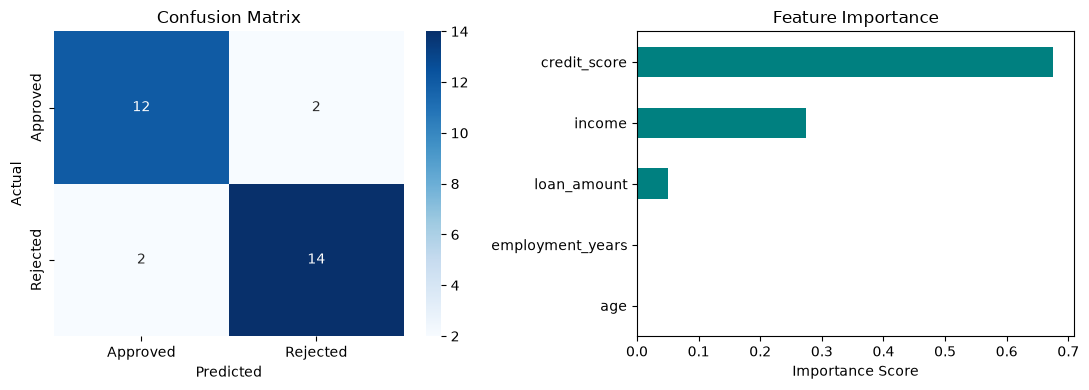

In [4]:
y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {acc * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=['Approved', 'Rejected'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Approved', 'Rejected'],
            yticklabels=['Approved', 'Rejected'])
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# Feature Importance
importances = pd.Series(model.feature_importances_, index=features).sort_values()
importances.plot(kind='barh', color='teal', ax=axes[1])
axes[1].set_title('Feature Importance')
axes[1].set_xlabel('Importance Score')

plt.tight_layout()
plt.show()

## 4. Visualize Decision Tree

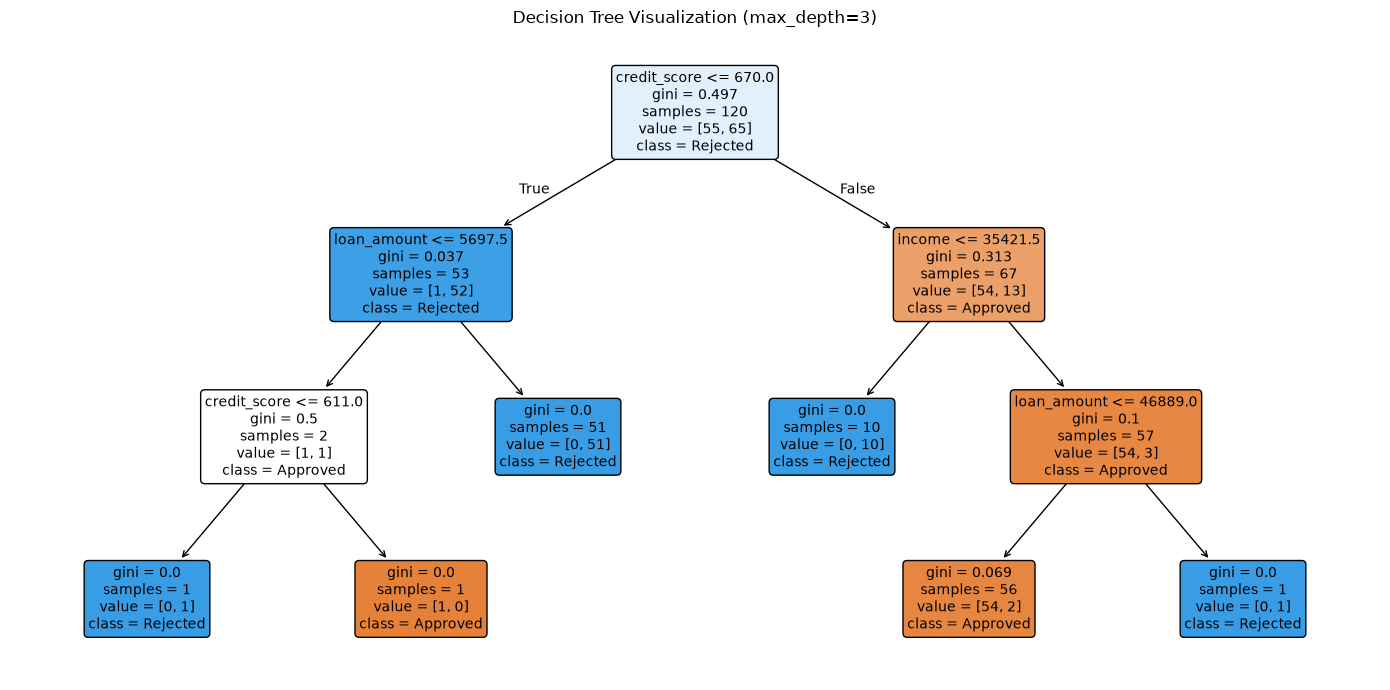

In [5]:
plt.figure(figsize=(14, 7))
plot_tree(model, feature_names=features, class_names=model.classes_,
          filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree Visualization (max_depth=3)")
plt.tight_layout()
plt.show()

## 5. Test on New Applicants

In [6]:
sample_applicants = pd.DataFrame([
    {'age': 32, 'income': 75000, 'credit_score': 720, 'loan_amount': 20000, 'employment_years': 5},
    {'age': 24, 'income': 28000, 'credit_score': 580, 'loan_amount': 35000, 'employment_years': 1},
    {'age': 45, 'income': 92000, 'credit_score': 680, 'loan_amount': 25000, 'employment_years': 10},
    {'age': 29, 'income': 42000, 'credit_score': 610, 'loan_amount': 40000, 'employment_years': 2}
])

for idx, row in sample_applicants.iterrows():
    single_df = pd.DataFrame([row])
    pred = model.predict(single_df)[0]
    probs = model.predict_proba(single_df)[0]
    prob_dict = {c: f"{p*100:.1f}%" for c, p in zip(model.classes_, probs)}
    
    print(f"Applicant {idx+1}: Income=${row['income']}, Credit={row['credit_score']}, Loan=${row['loan_amount']}")
    print(f"Result     : [ {pred.upper()} ] | Confidence: {prob_dict}\n")

Applicant 1: Income=$75000, Credit=720, Loan=$20000
Result     : [ APPROVED ] | Confidence: {'Approved': '96.4%', 'Rejected': '3.6%'}

Applicant 2: Income=$28000, Credit=580, Loan=$35000
Result     : [ REJECTED ] | Confidence: {'Approved': '0.0%', 'Rejected': '100.0%'}

Applicant 3: Income=$92000, Credit=680, Loan=$25000
Result     : [ APPROVED ] | Confidence: {'Approved': '96.4%', 'Rejected': '3.6%'}

Applicant 4: Income=$42000, Credit=610, Loan=$40000
Result     : [ REJECTED ] | Confidence: {'Approved': '0.0%', 'Rejected': '100.0%'}

